# Évaluation de trois modèles de Computer Vision

**Un notebook Colab — trois datasets spécialisés**

| Tâche | Dataset | Modèle | Métriques sur le test (10 %) |
|---|---|---|---|
| Object Detection | Brain Tumor (Ultralytics) | YOLO11n | Precision, Recall, mAP@50, mAP@50:95 |
| Instance Segmentation | Apple segmentation | YOLO11n-seg | Mask Precision, Mask Recall, Mask mAP@50, Mask mAP@50:95 |
| Semantic Segmentation | | U-Net compact | Pixel Accuracy, IoU, mIoU, Dice |

Pour **chaque dataset**, redivision aléatoire reproductible : **70 % train, 20 % validation, 10 % test**. Le test n'est utilisé qu'après l'entraînement. Les métriques entre tâches ne doivent pas être directement comparées (datasets et critères différents).

> Configuration Colab : *Exécution → Modifier le type d'exécution → GPU T4*. Le téléchargement et l'entraînement nécessitent Internet. Les entraînements prennent du temps; ajuster `EPOCHS` si nécessaire.

## 0. Installation et environnement

In [ ]:
%pip -q install ultralytics torchvision pyyaml scikit-learn tqdm matplotlib pillow

In [ ]:
import random, shutil, yaml, numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
ROOT = Path('/content/cv_evaluation'); ROOT.mkdir(parents=True, exist_ok=True)
EPOCHS_DET = 12
EPOCHS_INST = 12
EPOCHS_SEM = 8
IMGSZ_YOLO = 416
DEVICE_YOLO = 0 if torch.cuda.is_available() else 'cpu'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)

def split_70_20_10(items, seed=SEED):
    items = sorted(items, key=str)
    assert len(items) >= 10, 'Pas assez de données'
    train, remaining = train_test_split(items, test_size=0.30, random_state=seed)
    val, test = train_test_split(remaining, test_size=1/3, random_state=seed)
    assert not(set(train)&set(val) or set(train)&set(test) or set(val)&set(test))
    return {'train': train, 'val': val, 'test': test}

def print_split(splits, label):
    counts = {key:len(value) for key,value in splits.items()}
    total=sum(counts.values()); print(label, counts, {k: f'{v/total:.1%}' for k,v in counts.items()})


Device: cuda


## 1. Object Detection — Brain Tumor

Dataset de radiographies annotées avec des *bounding boxes*. Le dataset d'origine est téléchargé automatiquement par Ultralytics. Nous réunissons ses images d'origine puis recréons une division 70/20/10 pour éviter de réutiliser son découpage initial.

**Note :** les images médicales illustrent uniquement l'évaluation informatique et ne constituent pas un outil de diagnostic.

In [ ]:
# Premier appel : Ultralytics télécharge le jeu via sa configuration officielle.
# Le jeu est léger (~4,2 Mo).
from ultralytics.data.utils import check_det_dataset
from ultralytics.utils import SETTINGS

def load_ultra_dataset(config_name):
    cfg = check_det_dataset(config_name, autodownload=True)
    root = Path(cfg['path'])
    print(config_name, '->', root)
    return root, cfg

def discover_pairs(root):
    pairs = []
    valid_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
    for image in sorted((root/'images').rglob('*')):
        if not image.is_file() or image.suffix.lower() not in valid_exts: continue
        # Support layout images/train/xxx -> labels/train/xxx.txt
        rel = image.relative_to(root/'images')
        label = root/'labels'/rel.with_suffix('.txt')
        if label.exists(): pairs.append((image,label))
    if not pairs: raise RuntimeError(f'Aucune paire image/annotation trouvée dans {root}')
    return pairs

def repartition_yolo(source_root, out_root, label):
    pairs = discover_pairs(source_root)
    splits = split_70_20_10(pairs)
    if out_root.exists(): shutil.rmtree(out_root)
    for part, entries in splits.items():
        for j,(im,lab) in enumerate(entries):
            # noms garantis uniques, même si l'original possède plusieurs dossiers
            name=f'{j:05d}_{im.stem}'
            (out_root/'images'/part).mkdir(parents=True,exist_ok=True)
            (out_root/'labels'/part).mkdir(parents=True,exist_ok=True)
            shutil.copy2(im, out_root/'images'/part/(name+im.suffix.lower()))
            shutil.copy2(lab, out_root/'labels'/part/(name+'.txt'))
    print_split(splits,label)
    return splits

DET_SRC, DET_CFG = load_ultra_dataset('brain-tumor.yaml')
DET_ROOT = ROOT/'brain_tumor_702010'
det_split = repartition_yolo(DET_SRC, DET_ROOT, 'Détection')
det_yaml = DET_ROOT/'data.yaml'
det_yaml.write_text(yaml.safe_dump({
    'path':str(DET_ROOT),'train':'images/train','val':'images/val','test':'images/test',
    'names':DET_CFG['names']}, sort_keys=False),encoding='utf-8')
print(det_yaml.read_text()[:700])

brain-tumor.yaml -> /content/datasets/brain-tumor
Détection {'train': 770, 'val': 220, 'test': 111} {'train': '69.9%', 'val': '20.0%', 'test': '10.1%'}
path: /content/cv_evaluation/brain_tumor_702010
train: images/train
val: images/val
test: images/test
names:
  0: negative
  1: positive



In [ ]:
det_model = YOLO('yolo11n.pt')
det_model.train(data=str(det_yaml), epochs=EPOCHS_DET, imgsz=IMGSZ_YOLO,
                batch=8, device=DEVICE_YOLO, seed=SEED, project=str(ROOT/'runs'), name='detection',
                exist_ok=True, plots=True, workers=2)
det_model = YOLO(str(ROOT/'runs'/'detection'/'weights'/'best.pt'))
det_test = det_model.val(data=str(det_yaml), split='test', imgsz=IMGSZ_YOLO, device=DEVICE_YOLO, plots=True)
det_scores = {'Precision':float(det_test.box.mp), 'Recall':float(det_test.box.mr),
              'mAP50':float(det_test.box.map50), 'mAP50-95':float(det_test.box.map)}
print('Détection — test:', det_scores)

Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cv_evaluation/brain_tumor_702010/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=detection, nbs=64, nms=None, opset=None

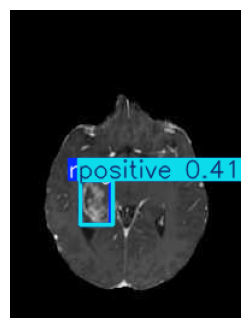

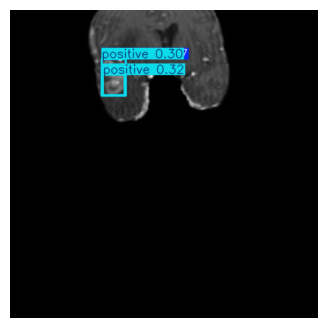

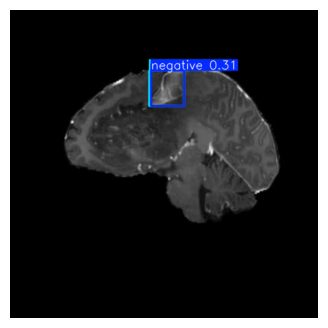

In [ ]:
det_examples = list((DET_ROOT/'images'/'test').glob('*'))[:3]
for result in det_model.predict(source=[str(x) for x in det_examples], conf=0.25, verbose=False):
    plt.figure(figsize=(7,4)); plt.imshow(result.plot()[...,::-1]); plt.axis('off'); plt.show()

## 2. Instance Segmentation — Package-Seg

Dataset de colis avec **masques polygonaux individuels**. Les résultats distinguent chaque colis, même lorsque plusieurs colis sont visibles. La métrique principale est **Mask mAP**, pas la mAP des bounding boxes.

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="fh53Gat2z63aHYIf423u")
project = rf.workspace("ettdija").project("appledetect-5dpv2")
version = project.version(5)
dataset = version.download("coco-segmentation")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
import json
import yaml
import shutil
from pathlib import Path
from ultralytics import YOLO

# Définition des dossiers
roboflow_dir = Path('/content/Appledetect-5')
yolo_dir = ROOT / 'apple_yolo_dataset'
yolo_dir.mkdir(parents=True, exist_ok=True)

# Fonction de conversion de COCO segmentation vers YOLO segmentation
def convert_coco_to_yolo(coco_json_path, images_src_dir, subset):
    images_dst_dir = yolo_dir / 'images' / subset
    labels_dst_dir = yolo_dir / 'labels' / subset
    images_dst_dir.mkdir(parents=True, exist_ok=True)
    labels_dst_dir.mkdir(parents=True, exist_ok=True)

    with open(coco_json_path, 'r') as f:
        coco = json.load(f)

    # Indexation des images et annotations
    id_to_image = {img['id']: img for img in coco['images']}
    img_annotations = {img['id']: [] for img in coco['images']}
    for ann in coco['annotations']:
        img_id = ann['image_id']
        if img_id in img_annotations:
            img_annotations[img_id].append(ann)

    # Écriture des fichiers YOLO TXT
    for img_id, anns in img_annotations.items():
        img_info = id_to_image[img_id]
        file_name = img_info['file_name']
        width = img_info['width']
        height = img_info['height']

        src_img_path = images_src_dir / file_name
        if not src_img_path.exists():
            continue

        # Copie de l'image
        shutil.copy2(src_img_path, images_dst_dir / file_name)

        # Création du fichier d'annotation TXT
        txt_name = Path(file_name).with_suffix('.txt')
        with open(labels_dst_dir / txt_name, 'w') as out_f:
            for ann in anns:
                # ID de classe (toujours 0 pour 'apple')
                class_id = 0
                segmentation = ann.get('segmentation', [])
                if not segmentation:
                    continue
                # Normalisation des coordonnées de segmentation
                poly = segmentation[0]
                normalized_poly = []
                for i in range(0, len(poly), 2):
                    x_norm = poly[i] / width
                    y_norm = poly[i+1] / height
                    normalized_poly.append(f"{x_norm:.6f} {y_norm:.6f}")
                out_f.write(f"{class_id} {' '.join(normalized_poly)}\n")

# Conversion pour chaque split
convert_coco_to_yolo(roboflow_dir / 'train' / '_annotations.coco.json', roboflow_dir / 'train', 'train')
convert_coco_to_yolo(roboflow_dir / 'valid' / '_annotations.coco.json', roboflow_dir / 'valid', 'val')
convert_coco_to_yolo(roboflow_dir / 'test' / '_annotations.coco.json', roboflow_dir / 'test', 'test')

# Génération du data.yaml final
inst_yaml = yolo_dir / 'data.yaml'
config_data = {
    'path': str(yolo_dir),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {0: 'apple'}
}
with open(inst_yaml, 'w') as f:
    yaml.safe_dump(config_data, f, sort_keys=False)

print("Configuration YOLO créée avec succès à l'emplacement :", inst_yaml)

# Entraînement du modèle YOLO de segmentation d'instances
inst_model = YOLO('yolo11n-seg.pt')
inst_model.train(data=str(inst_yaml), epochs=EPOCHS_INST, imgsz=IMGSZ_YOLO,
                 batch=8, device=DEVICE_YOLO, seed=SEED, project=str(ROOT/'runs'), name='instances',
                 exist_ok=True, plots=True, workers=2)

# Validation et extraction des métriques de test
inst_model = YOLO(str(ROOT/'runs'/'instances'/'weights'/'best.pt'))
inst_test = inst_model.val(data=str(inst_yaml), split='test', imgsz=IMGSZ_YOLO, device=DEVICE_YOLO, plots=True)
inst_scores = {'Mask Precision':float(inst_test.seg.mp), 'Mask Recall':float(inst_test.seg.mr),
               'Mask mAP50':float(inst_test.seg.map50), 'Mask mAP50-95':float(inst_test.seg.map)}
print('Instances — test:', inst_scores)

Configuration YOLO créée avec succès à l'emplacement : /content/cv_evaluation/apple_yolo_dataset/data.yaml
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cv_evaluation/apple_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, 

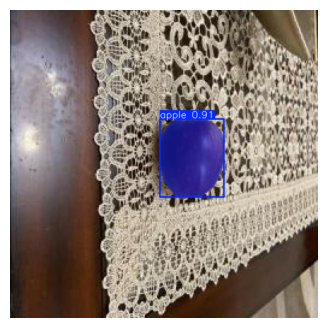

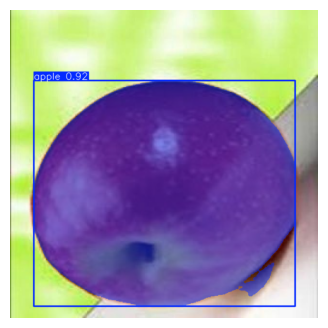

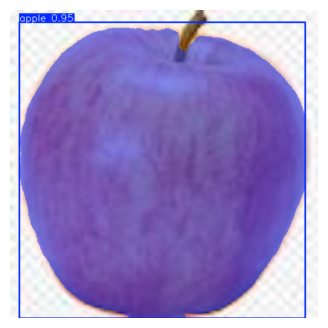

In [ ]:
inst_examples = list((yolo_dir/'images'/'test').glob('*'))[:3]
for result in inst_model.predict(source=[str(x) for x in inst_examples], conf=0.25, verbose=False):
    plt.figure(figsize=(7,4)); plt.imshow(result.plot()[...,::-1]); plt.axis('off'); plt.show()

## 3. Semantic Segmentation — Oxford-IIIT Pet

Ce dataset contient des images de chats/chiens et des masques *trimap*. On entraîne une petite **U-Net binaire** à distinguer *animal / arrière-plan*. Les pixels de contour (`label=3`) sont ignorés pour que l'évaluation porte sur les régions clairement annotées. Le dataset comporte son découpage officiel, mais on combine les deux parties avant de créer notre **70/20/10** reproductible.

In [ ]:
%pip install -U "datasets" "pyarrow>=15.0.0"

In [ ]:


from datasets import load_dataset
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

# Dataset ADE20K : images + masques sémantiques
dataset = load_dataset(
    "merve/scene_parse_150",
    split="train[:500]"
)

# Séparation : 70% train, 20% validation, 10% test
split1 = dataset.train_test_split(
    test_size=0.30,
    seed=42
)

split2 = split1["test"].train_test_split(
    test_size=1/3,
    seed=42
)

train_data = split1["train"]
val_data = split2["train"]
test_data = split2["test"]

print("Train :", len(train_data))
print("Validation :", len(val_data))
print("Test :", len(test_data))

# Classe cible : mur (annotation ADE20K = 1)
class SemanticDataset(Dataset):
    def __init__(self, data, size=128):
        self.data = data
        self.size = size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]

        image = item["image"].convert("RGB").resize(
            (self.size, self.size),
            Image.Resampling.BILINEAR
        )

        mask = item["annotation"].resize(
            (self.size, self.size),
            Image.Resampling.NEAREST
        )

        x = torch.from_numpy(
            np.array(image, dtype=np.float32)
            .transpose(2, 0, 1) / 255.0
        )

        # Segmentation binaire : mur vs autres pixels
        y = (np.array(mask) == 1).astype(np.int64)

        return x, torch.from_numpy(y)

train_loader = DataLoader(
    SemanticDataset(train_data),
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    SemanticDataset(val_data),
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    SemanticDataset(test_data),
    batch_size=16,
    shuffle=False
)

x, y = next(iter(train_loader))

print("Images :", x.shape)
print("Masques :", y.shape)
print("Classes :", torch.unique(y).tolist())


README.md:   0%|          | 0.00/31.7k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  212MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 89.1MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  442MB            

... (3 outputs left out)

Generating test split:   0%|          | 0/3352 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20210 [00:00<?, ? examples/s]

Train : 350
Validation : 100
Test : 50
Images : torch.Size([16, 3, 128, 128])
Masques : torch.Size([16, 128, 128])
Classes : [0, 1]


In [ ]:
import cv2
import numpy as np
from pathlib import Path
import yaml
from ultralytics import YOLO

# Création du dossier pour le dataset sémantique au format YOLO
sem_yolo_dir = ROOT / 'semantic_yolo_dataset'
sem_yolo_dir.mkdir(parents=True, exist_ok=True)

def export_to_yolo_seg(dataset_split, subset):
    imgs_dir = sem_yolo_dir / 'images' / subset
    lbls_dir = sem_yolo_dir / 'labels' / subset
    imgs_dir.mkdir(parents=True, exist_ok=True)
    lbls_dir.mkdir(parents=True, exist_ok=True)

    for idx, item in enumerate(dataset_split):
        # Sauvegarde de l'image
        img = item['image'].convert('RGB')
        img_name = f'{idx:05d}.jpg'
        img_path = imgs_dir / img_name
        img.save(img_path)

        # Extraction du masque pour la classe cible (mur = 1 dans ADE20K)
        mask = np.array(item['annotation'])
        binary_mask = (mask == 1).astype(np.uint8) * 255

        # Recherche des contours pour créer les polygones YOLO
        contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        h, w = binary_mask.shape
        txt_path = lbls_dir / f'{idx:05d}.txt'

        with open(txt_path, 'w') as f:
            for contour in contours:
                if len(contour) < 3:  # Un polygone a besoin d'au moins 3 points
                    continue
                # Normalisation des coordonnées
                coords = contour.reshape(-1, 2)
                normalized_coords = []
                for x, y in coords:
                    normalized_coords.append(f"{x/w:.6f} {y/h:.6f}")
                f.write(f"0 {' '.join(normalized_coords)}\n")

# Exportation des splits
export_to_yolo_seg(train_data, 'train')
export_to_yolo_seg(val_data, 'val')
export_to_yolo_seg(test_data, 'test')

# Création du fichier de configuration YAML
sem_yaml_path = sem_yolo_dir / 'data.yaml'
sem_config = {
    'path': str(sem_yolo_dir),
    'train': 'images/train',
    'val': 'images/val',
    'test': 'images/test',
    'names': {0: 'wall'}
}
with open(sem_yaml_path, 'w') as f:
    yaml.safe_dump(sem_config, f, sort_keys=False)

print("Dataset sémantique exporté avec succès au format YOLO !")

Dataset sémantique exporté avec succès au format YOLO !


New https://pypi.org/project/ultralytics/8.4.200 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/cv_evaluation/semantic_yolo_dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, mod

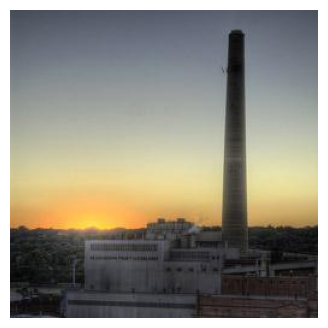

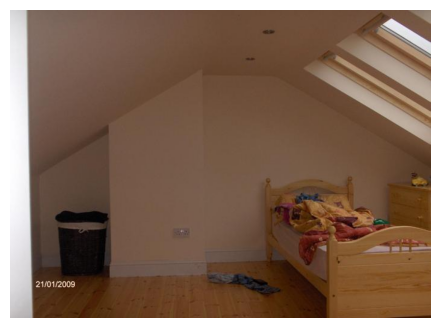

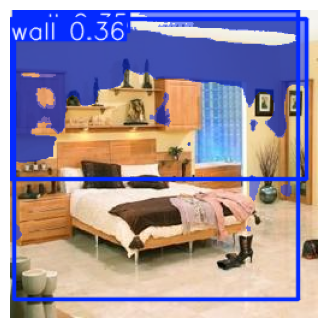

In [ ]:
# Entraînement du modèle YOLO de segmentation pour la tâche sémantique (murs)
sem_yolo_model = YOLO('yolo11n-seg.pt')
sem_yolo_model.train(data=str(sem_yaml_path), epochs=EPOCHS_SEM, imgsz=IMGSZ_YOLO,
                     batch=8, device=DEVICE_YOLO, seed=SEED, project=str(ROOT/'runs'), name='semantic_yolo',
                     exist_ok=True, plots=True, workers=2)

# Validation sur le jeu de test
sem_yolo_model = YOLO(str(ROOT/'runs'/'semantic_yolo'/'weights'/'best.pt'))
sem_yolo_test = sem_yolo_model.val(data=str(sem_yaml_path), split='test', imgsz=IMGSZ_YOLO, device=DEVICE_YOLO, plots=True)

# Extraction des métriques de test
sem_yolo_scores = {
    'Mask Precision': float(sem_yolo_test.seg.mp),
    'Mask Recall': float(sem_yolo_test.seg.mr),
    'Mask mAP50': float(sem_yolo_test.seg.map50),
    'Mask mAP50-95': float(sem_yolo_test.seg.map)
}
print('Segmentation Sémantique (YOLO) — test:', sem_yolo_scores)

# Visualisation de quelques prédictions sur le jeu de test
import matplotlib.pyplot as plt
sem_examples = list((sem_yolo_dir/'images'/'test').glob('*'))[:3]
for result in sem_yolo_model.predict(source=[str(x) for x in sem_examples], conf=0.25, verbose=False):
    plt.figure(figsize=(7,4))
    plt.imshow(result.plot()[...,::-1])
    plt.axis('off')
    plt.show()

Epoch 01 | loss=0.5749 | val mIoU=0.4287
Epoch 02 | loss=0.4675 | val mIoU=0.4757
Epoch 03 | loss=0.4191 | val mIoU=0.4289
Epoch 04 | loss=0.3859 | val mIoU=0.4292
Epoch 05 | loss=0.3697 | val mIoU=0.4248
Epoch 06 | loss=0.3607 | val mIoU=0.4585
Epoch 07 | loss=0.3490 | val mIoU=0.4292
Epoch 08 | loss=0.3444 | val mIoU=0.5512
Segmentation sémantique — TEST: {'Pixel Accuracy': 0.846148669719696, 'IoU background': 0.8385902643203735, 'IoU animal': 0.23334509134292603, 'mIoU': 0.5359677076339722, 'Dice animal': 0.37839382886886597}


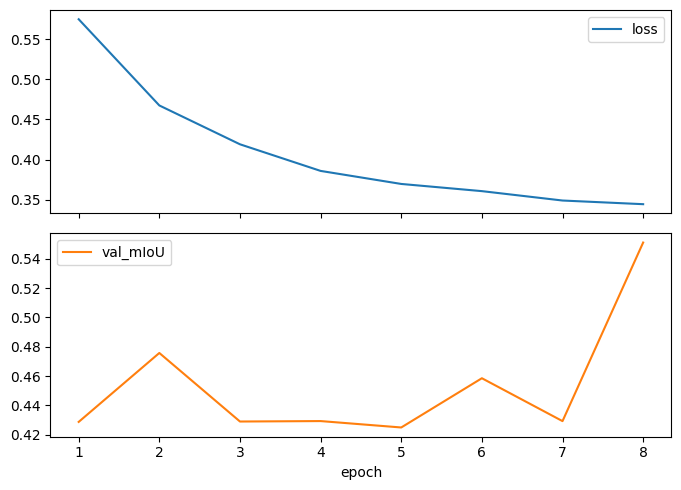

In [ ]:
class ConvBlock(nn.Module):
    def __init__(self,a,b):
        super().__init__(); self.net=nn.Sequential(nn.Conv2d(a,b,3,padding=1),nn.BatchNorm2d(b),nn.ReLU(inplace=True),
                                                  nn.Conv2d(b,b,3,padding=1),nn.BatchNorm2d(b),nn.ReLU(inplace=True))
    def forward(self,x): return self.net(x)
class SmallUNet(nn.Module):
    def __init__(self):
        super().__init__(); self.e1=ConvBlock(3,16); self.e2=ConvBlock(16,32); self.e3=ConvBlock(32,64)
        self.center=ConvBlock(64,128); self.d3=ConvBlock(128+64,64); self.d2=ConvBlock(64+32,32)
        self.d1=ConvBlock(32+16,16); self.out=nn.Conv2d(16,2,1)
    def forward(self,x):
        a=self.e1(x); b=self.e2(F.max_pool2d(a,2)); c=self.e3(F.max_pool2d(b,2))
        z=self.center(F.max_pool2d(c,2))
        z=self.d3(torch.cat([F.interpolate(z,size=c.shape[-2:],mode='bilinear',align_corners=False),c],1))
        z=self.d2(torch.cat([F.interpolate(z,size=b.shape[-2:],mode='bilinear',align_corners=False),b],1))
        z=self.d1(torch.cat([F.interpolate(z,size=a.shape[-2:],mode='bilinear',align_corners=False),a],1))
        return self.out(z)

sem_model=SmallUNet().to(DEVICE)
optimizer=torch.optim.Adam(sem_model.parameters(),lr=1e-3)
criterion=nn.CrossEntropyLoss(ignore_index=255)

def pixel_confusion(model,loader):
    cm=torch.zeros((2,2),dtype=torch.long)
    model.eval()
    with torch.no_grad():
        for xb,yb in loader:
            pred=model(xb.to(DEVICE)).argmax(1).cpu()
            valid=yb!=255
            z=2*yb[valid]+pred[valid]
            cm+=torch.bincount(z,minlength=4).reshape(2,2)
    return cm

def semantic_metrics(cm):
    cm=cm.float(); tp=cm.diag(); union=cm.sum(1)+cm.sum(0)-tp
    iou=tp/union.clamp(min=1); dice=2*tp/(cm.sum(1)+cm.sum(0)).clamp(min=1)
    return {'Pixel Accuracy':(tp.sum()/cm.sum()).item(), 'IoU background':iou[0].item(),
            'IoU animal':iou[1].item(), 'mIoU':iou.mean().item(), 'Dice animal':dice[1].item()}

best_val=-1; history=[]
for epoch in range(1,EPOCHS_SEM+1):
    sem_model.train(); running=0
    for xb,yb in train_loader:
        xb,yb=xb.to(DEVICE),yb.to(DEVICE)
        optimizer.zero_grad(); loss=criterion(sem_model(xb),yb)
        loss.backward(); optimizer.step(); running+=loss.item()
    val_scores=semantic_metrics(pixel_confusion(sem_model,val_loader))
    history.append({'epoch':epoch,'loss':running/len(train_loader),'val_mIoU':val_scores['mIoU']})
    print(f'Epoch {epoch:02d} | loss={running/len(train_loader):.4f} | val mIoU={val_scores["mIoU"]:.4f}')
    if val_scores['mIoU']>best_val:
        best_val=val_scores['mIoU']; torch.save(sem_model.state_dict(),ROOT/'unet_best.pth')
sem_model.load_state_dict(torch.load(ROOT/'unet_best.pth',map_location=DEVICE,weights_only=True))
sem_cm=pixel_confusion(sem_model,test_loader)
sem_scores=semantic_metrics(sem_cm)
print('Segmentation sémantique — TEST:',sem_scores)
pd.DataFrame(history).plot(x='epoch',y=['loss','val_mIoU'],subplots=True,figsize=(7,5)); plt.tight_layout(); plt.show()

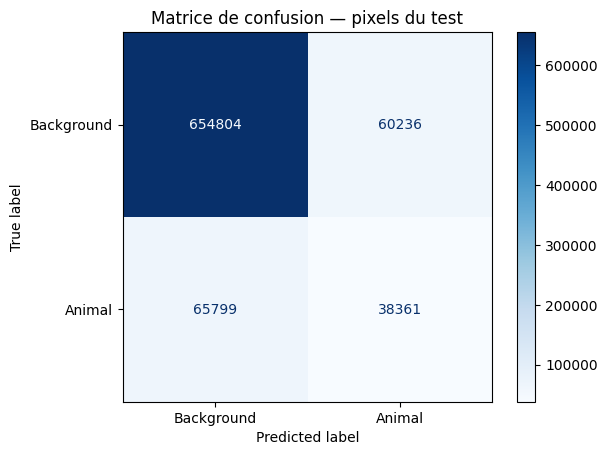

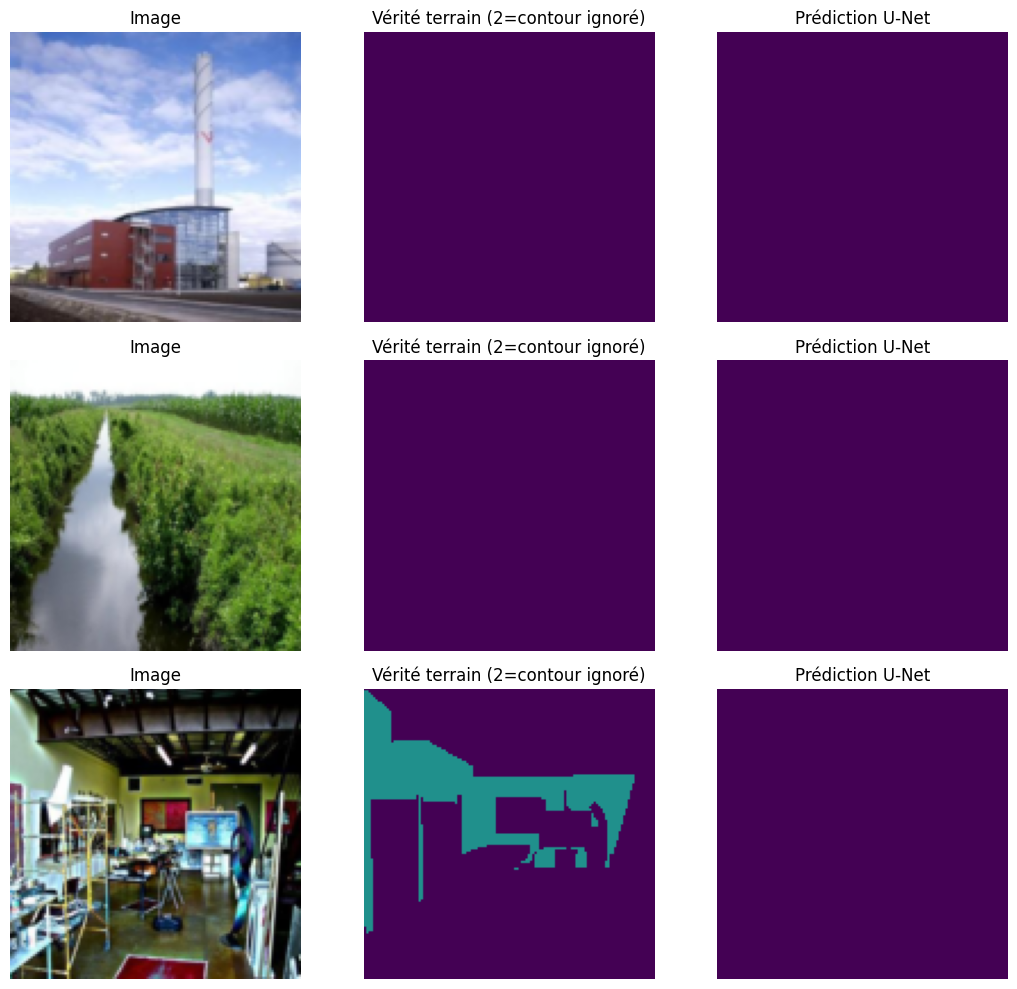

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(sem_cm.numpy(),display_labels=['Background','Animal']).plot(values_format='d',cmap='Blues')
plt.title('Matrice de confusion — pixels du test'); plt.show()
sem_model.eval()
images, masks=next(iter(test_loader))
with torch.no_grad(): preds=sem_model(images[:3].to(DEVICE)).argmax(1).cpu()
fig,axes=plt.subplots(3,3,figsize=(11,10))
for j in range(3):
    axes[j,0].imshow(images[j].permute(1,2,0)); axes[j,0].set_title('Image')
    gt=masks[j].numpy().copy(); gt[gt==255]=2
    axes[j,1].imshow(gt,vmin=0,vmax=2,cmap='viridis'); axes[j,1].set_title('Vérité terrain (2=contour ignoré)')
    axes[j,2].imshow(preds[j],vmin=0,vmax=1,cmap='viridis'); axes[j,2].set_title('Prédiction U-Net')
    for a in axes[j]: a.axis('off')
plt.tight_layout(); plt.show()

## 4. Synthèse des métriques sur les jeux de test

Les chiffres affichés ci-dessous sont obtenus **uniquement sur les 10 % réservés au test**. Les métriques ne comparent pas la difficulté des tâches entre elles, car les données sont différentes.

In [ ]:
rows=[]
rows += [{'Tâche':'Object Detection','Dataset':'Brain Tumor','Métrique':k,'Test':v} for k,v in det_scores.items()]
rows += [{'Tâche':'Instance Segmentation','Dataset':'Apple-seg','Métrique':k,'Test':v} for k,v in inst_scores.items()]
rows += [{'Tâche':'Semantic Segmentation','Dataset':'semantic_yolo_dataset','Métrique':k,'Test':v} for k,v in sem_scores.items()]
comparison=pd.DataFrame(rows)
display(comparison.style.format({'Test':'{:.4f}'}))
comparison.to_csv(ROOT/'cv_metrics_test.csv',index=False)
print('Résultats enregistrés dans',ROOT/'cv_metrics_test.csv')

,Tâche,Dataset,Métrique,Test
0,Object Detection,Brain Tumor,Precision,0.4999
1,Object Detection,Brain Tumor,Recall,0.8563
2,Object Detection,Brain Tumor,mAP50,0.5785
3,Object Detection,Brain Tumor,mAP50-95,0.4294
4,Instance Segmentation,Apple-seg,Mask Precision,0.9792
5,Instance Segmentation,Apple-seg,Mask Recall,0.8780
6,Instance Segmentation,Apple-seg,Mask mAP50,0.9596
7,Instance Segmentation,Apple-seg,Mask mAP50-95,0.8795
8,Semantic Segmentation,semantic_yolo_dataset,Pixel Accuracy,0.8461
9,Semantic Segmentation,semantic_yolo_dataset,IoU background,0.8386


Résultats enregistrés dans /content/cv_evaluation/cv_metrics_test.csv


### Interprétation pour la présentation

- **Détection :** la mAP vérifie si les boîtes prédites correspondent aux boîtes annotées, en tenant compte de l'IoU.
- **Instances :** la Mask mAP mesure la précision des masques individuels, après appariement aux instances annotées.
- **Sémantique :** la mIoU mesure le chevauchement des régions par classe ; Dice insiste également sur le recouvrement.
- Une validation à 20 % sert à guider l'entraînement et sélectionner le modèle ; les **10 % de test** servent à rendre compte de la performance finale.

**Références :** [Ultralytics Brain Tumor](https://docs.ultralytics.com/datasets/detect/brain-tumor/), [Ultralytics Package-Seg](https://docs.ultralytics.com/datasets/segment/package-seg/), [Torchvision Oxford-IIIT Pet](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.OxfordIIITPet.html).